<a href="https://colab.research.google.com/github/kpate18/ECGR-4105/blob/main/homework%205/Problem_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Training samples: 436
Validation samples: 109

* Learning Rate: 0.1
Epoch  500 | Train Loss = 0.437832 | Val Loss = 0.743571 | Val R2 = 0.5464
Epoch 1000 | Train Loss = 0.437832 | Val Loss = 0.743571 | Val R2 = 0.5464
Epoch 1500 | Train Loss = 0.437832 | Val Loss = 0.743571 | Val R2 = 0.5464
Epoch 2000 | Train Loss = 0.437832 | Val Loss = 0.743571 | Val R2 = 0.5464
Epoch 2500 | Train Loss = 0.437832 | Val Loss = 0.743571 | Val R2 = 0.5464
Epoch 3000 | Train Loss = 0.437832 | Val Loss = 0.743571 | Val R2 = 0.5464
Epoch 3500 | Train Loss = 0.437832 | Val Loss = 0.743571 | Val R2 = 0.5464
Epoch 4000 | Train Loss = 0.437832 | Val Loss = 0.743571 | Val R2 = 0.5464
Epoch 4500 | Train Loss = 0.437832 | Val Loss = 0.743571 | Val R2 = 0.5464
Epoch 5000 | Train Loss = 0.437832 | Val Loss = 0.743571 | Val R2 = 0.5464

Final Validation Loss: 0.7435711271453694
Final Validation R2: 0.5464062355495863

* Learning Rate: 0.01
Epoch  500 | Train Loss = 0.437832 | Val Loss = 0.743587 | Val R2 = 0.5464
E

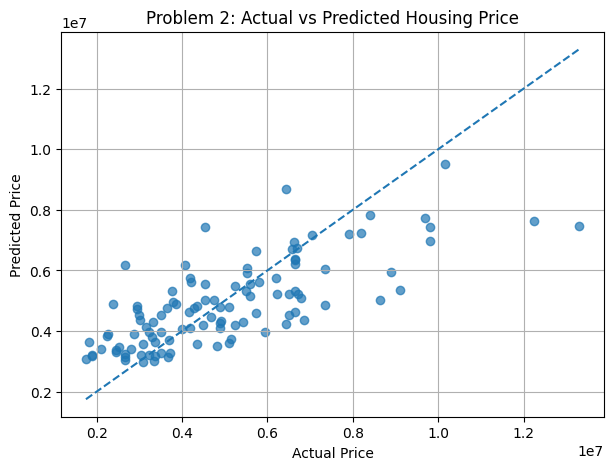

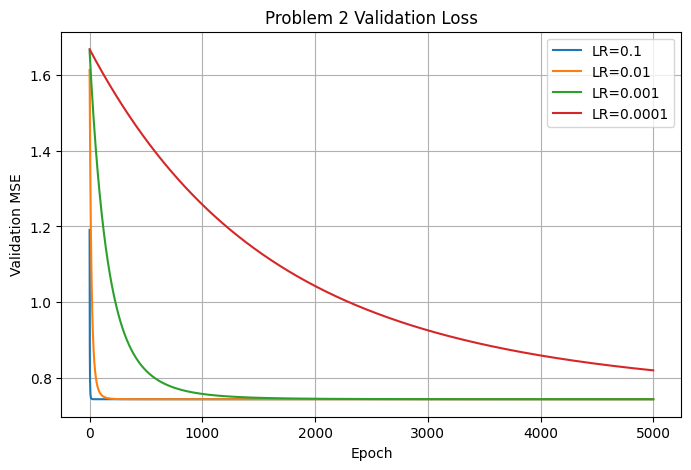

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
df = pd.read_csv("Housing.csv")

df.head()
features_p2 = [
    "area",
    "bedrooms",
    "bathrooms",
    "stories",
    "parking"
]

X = df[features_p2].values.astype(float)

y = df["price"].values.astype(float)

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Validation samples:", X_val.shape[0])

X_mean = X_train.mean(axis=0)
X_std = X_train.std(axis=0)

y_mean = y_train.mean()
y_std = y_train.std()

X_train_scaled = (X_train - X_mean) / X_std
X_val_scaled = (X_val - X_mean) / X_std

y_train_scaled = (y_train - y_mean) / y_std
y_val_scaled = (y_val - y_mean) / y_std

def linear_model(X, w, b):
    return X @ w + b

def train_housing(
    X_train,
    y_train,
    X_val,
    y_val,
    learning_rate,
    epochs=5000
):

    n_features = X_train.shape[1]

    w = np.zeros(n_features)
    b = 0.0

    train_history = []
    val_history = []
    r2_history = []

    for epoch in range(1, epochs + 1):

        # -------------------------
        # Training prediction
        # -------------------------
        train_pred = X_train @ w + b

        train_error = train_pred - y_train

        train_loss = np.mean(train_error ** 2)

        # -------------------------
        # Gradients
        # -------------------------
        grad_w = (
            2 / len(y_train)
        ) * (X_train.T @ train_error)

        grad_b = 2 * np.mean(train_error)

        # -------------------------
        # Update parameters
        # -------------------------
        w = w - learning_rate * grad_w
        b = b - learning_rate * grad_b

        # -------------------------
        # Validation
        # -------------------------
        val_pred = X_val @ w + b

        val_loss = np.mean(
            (val_pred - y_val) ** 2
        )

        val_r2 = r2_score(
            y_val,
            val_pred
        )

        train_history.append(train_loss)
        val_history.append(val_loss)
        r2_history.append(val_r2)

        if epoch % 500 == 0:

            print(
                f"Epoch {epoch:4d} | "
                f"Train Loss = {train_loss:.6f} | "
                f"Val Loss = {val_loss:.6f} | "
                f"Val R2 = {val_r2:.4f}"
            )

    return (
        w,
        b,
        train_history,
        val_history,
        r2_history
    )

learning_rates = [
    0.1,
    0.01,
    0.001,
    0.0001
]

results_p2 = {}

for lr in learning_rates:

    print(f"\n* Learning Rate: {lr}")

    w, b, train_loss, val_loss, r2 = train_housing(
        X_train_scaled,
        y_train_scaled,
        X_val_scaled,
        y_val_scaled,
        learning_rate=lr,
        epochs=5000
    )

    results_p2[lr] = {
        "w": w,
        "b": b,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "r2": r2
    }

    print("\nFinal Validation Loss:",
          val_loss[-1])

    print("Final Validation R2:",
          r2[-1])

best_lr_p2 = min(
    learning_rates,
    key=lambda lr:
    results_p2[lr]["val_loss"][-1]
)

best_p2 = results_p2[best_lr_p2]

print("Best Learning Rate:", best_lr_p2)

print(
    "Best Validation Loss:",
    best_p2["val_loss"][-1]
)

print(
    "Best Validation R2:",
    best_p2["r2"][-1]
)

w_scaled = best_p2["w"]
b_scaled = best_p2["b"]

w_original = (
    y_std * w_scaled / X_std
)

b_original = (
    y_mean
    + y_std * b_scaled
    - np.sum(w_original * X_mean)
)

print("\nOriginal-scale parameters:")

for feature, weight in zip(
    features_p2,
    w_original
):
    print(
        f"{feature:10s}: {weight:.4f}"
    )

print(f"bias      : {b_original:.4f}")

best_w = best_p2["w"]
best_b = best_p2["b"]

val_pred_scaled = (
    X_val_scaled @ best_w
    + best_b
)

val_pred_actual = (
    val_pred_scaled * y_std
    + y_mean
)

actual_mse = np.mean(
    (val_pred_actual - y_val) ** 2
)

actual_rmse = np.sqrt(actual_mse)

actual_r2 = r2_score(
    y_val,
    val_pred_actual
)

print("Validation MSE:", actual_mse)
print("Validation RMSE:", actual_rmse)
print("Validation R2:", actual_r2)

plt.figure(figsize=(7, 5))

plt.scatter(
    y_val,
    val_pred_actual,
    alpha=0.7
)

minimum = min(
    y_val.min(),
    val_pred_actual.min()
)

maximum = max(
    y_val.max(),
    val_pred_actual.max()
)

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")

plt.title(
    "Problem 2: Actual vs Predicted Housing Price"
)

plt.grid()

plt.show()

plt.figure(figsize=(8, 5))

for lr in learning_rates:

    plt.plot(
        results_p2[lr]["val_loss"],
        label=f"LR={lr}"
    )

plt.xlabel("Epoch")
plt.ylabel("Validation MSE")

plt.title(
    "Problem 2 Validation Loss"
)

plt.legend()
plt.grid()

plt.show()
